In [5]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv(
    "../data/raw/PS_20174392719_1491204439457_log.csv"
)

# Repeat preprocessing
df = df.drop(
    columns=["nameOrig", "nameDest", "isFlaggedFraud"]
)

df["errorBalanceOrig"] = (
    df["oldbalanceOrg"] - df["amount"] - df["newbalanceOrig"]
)

df["errorBalanceDest"] = (
    df["oldbalanceDest"] + df["amount"] - df["newbalanceDest"]
)

df = pd.get_dummies(
    df,
    columns=["type"],
    dtype=int
)

# Separate features and target
X = df.drop(columns=["isFraud"])
y = df["isFraud"]

# Recreate chronological split
train_end = df["step"].quantile(0.70)
validation_end = df["step"].quantile(0.85)

validation_mask = (
    (df["step"] > train_end) &
    (df["step"] <= validation_end)
)

X_val = X.loc[validation_mask]
y_val = y.loc[validation_mask]

print("Validation features:", X_val.shape)
print("Validation target:", y_val.shape)

Validation features: (980416, 13)
Validation target: (980416,)


In [2]:
import joblib

model = joblib.load(
    "../models/logistic_regression.pkl"
)

if "X_val" not in globals() and "X_test" in globals():
    X_val = X_test

y_prob = model.predict_proba(X_val)[:, 1]

In [3]:
y_prob = model.predict_proba(X_val)[:, 1]

print(y_prob[:10])

[1.01668361e-04 1.31176972e-04 2.18156486e-27 1.08516135e-04
 3.74197969e-25 5.48173742e-07 3.86323380e-07 7.24179082e-09
 8.40726454e-09 8.99761986e-05]


In [6]:
thresholds = [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

results = []

for threshold in thresholds:

    predictions = (y_prob >= threshold).astype(int)

    precision = precision_score(
        y_val,
        predictions,
        zero_division=0
    )

    recall = recall_score(
        y_val,
        predictions,
        zero_division=0
    )

    f1 = f1_score(
        y_val,
        predictions,
        zero_division=0
    )

    results.append({
        "Threshold": threshold,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1
    })

results_df = pd.DataFrame(results)

results_df

,Threshold,Precision,Recall,F1 Score
0,0.05,0.003852,0.996454,0.007675
1,0.10,0.004750,0.996454,0.009454
2,0.20,0.006437,0.996454,0.012791
3,0.30,0.008538,0.996454,0.016931
4,0.40,0.011755,0.996454,0.023235
5,0.50,0.017867,0.991135,0.035101
6,0.60,0.031344,0.964539,0.060714
7,0.70,0.049012,0.932624,0.093130
8,0.80,0.080959,0.886525,0.148368
9,0.90,0.170309,0.801418,0.280920


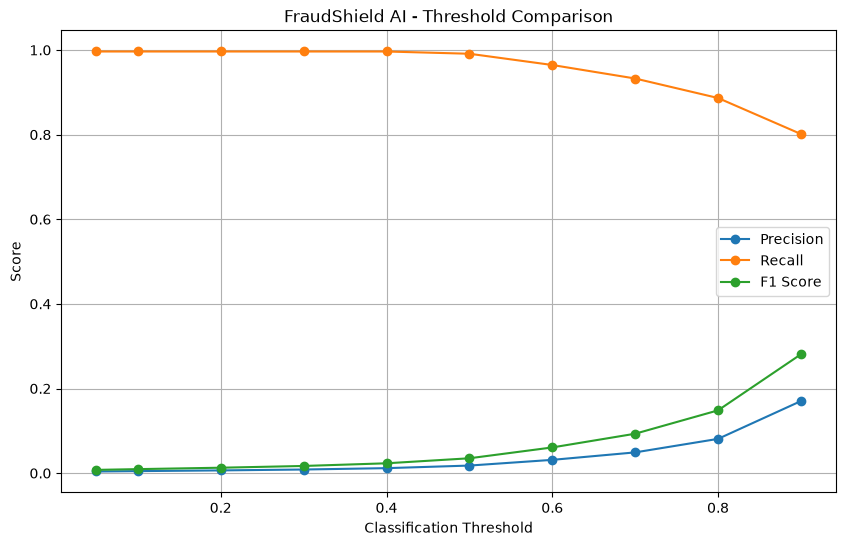

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["Threshold"],
    results_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    results_df["Threshold"],
    results_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    results_df["Threshold"],
    results_df["F1 Score"],
    marker="o",
    label="F1 Score"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("FraudShield AI - Threshold Comparison")

plt.legend()

plt.grid()

plt.show()